Imports & seeds

In [1]:
# 1.
import os
import time
import json
import csv
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fixed seed
SEED = 42
np.random.seed(SEED)

# Appropriate paths 
RAW_PATH = "../data/raw/parkinsons_updrs.data"
CLEAN_PATH = "../data/dataset_clean.csv"
RESULTS_PATH = "../results/results.csv"
FIG_DIR = "../results/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# To avoid dupes
if os.path.exists(RESULTS_PATH):
    os.remove(RESULTS_PATH)

sns.set_theme(style="whitegrid")

Data Loading

In [2]:
# 2. 
df = pd.read_csv(RAW_PATH)

print("Shape:", df.shape)
df.head()

Shape: (5875, 22)


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,...,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,...,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,...,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,1,72,0,25.6470,28.905,35.810,0.00528,0.000027,0.00191,0.00264,...,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,1,72,0,33.6420,29.187,36.375,0.00335,0.000020,0.00093,0.00130,...,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5875 entries, 0 to 5874
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   subject#       5875 non-null   int64  
 1   age            5875 non-null   int64  
 2   sex            5875 non-null   int64  
 3   test_time      5875 non-null   float64
 4   motor_UPDRS    5875 non-null   float64
 5   total_UPDRS    5875 non-null   float64
 6   Jitter(%)      5875 non-null   float64
 7   Jitter(Abs)    5875 non-null   float64
 8   Jitter:RAP     5875 non-null   float64
 9   Jitter:PPQ5    5875 non-null   float64
 10  Jitter:DDP     5875 non-null   float64
 11  Shimmer        5875 non-null   float64
 12  Shimmer(dB)    5875 non-null   float64
 13  Shimmer:APQ3   5875 non-null   float64
 14  Shimmer:APQ5   5875 non-null   float64
 15  Shimmer:APQ11  5875 non-null   float64
 16  Shimmer:DDA    5875 non-null   float64
 17  NHR            5875 non-null   float64
 18  HNR            5875

In [4]:
print(list(df.columns))

['subject#', 'age', 'sex', 'test_time', 'motor_UPDRS', 'total_UPDRS', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE']


In [5]:
# Column groups
TARGET = "total_UPDRS"
GROUP_COL = "subject#"
EXCLUDED = ["motor_UPDRS", "test_time"]   # per the assignment sheet

JITTER = ["Jitter(%)", "Jitter(Abs)", "Jitter:RAP", "Jitter:PPQ5", "Jitter:DDP"]
SHIMMER = ["Shimmer", "Shimmer(dB)", "Shimmer:APQ3", "Shimmer:APQ5", "Shimmer:APQ11", "Shimmer:DDA"]
OTHER_VOICE = ["NHR", "HNR", "RPDE", "DFA", "PPE"]
FEATURES = ["age", "sex"] + JITTER + SHIMMER + OTHER_VOICE   # 18 inputs

EDA

In [6]:
print("Rows, cols:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.dtypes

Rows, cols: (5875, 22)
Missing values: 0
Duplicate rows: 0


subject#           int64
age                int64
sex                int64
test_time        float64
motor_UPDRS      float64
total_UPDRS      float64
Jitter(%)        float64
Jitter(Abs)      float64
Jitter:RAP       float64
Jitter:PPQ5      float64
Jitter:DDP       float64
Shimmer          float64
Shimmer(dB)      float64
Shimmer:APQ3     float64
Shimmer:APQ5     float64
Shimmer:APQ11    float64
Shimmer:DDA      float64
NHR              float64
HNR              float64
RPDE             float64
DFA              float64
PPE              float64
dtype: object

In [7]:
df[FEATURES + [TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
age,5875.0,64.804936,8.821524,36.000000,58.000000,65.000000,72.000000,85.000000
sex,5875.0,0.317787,0.465656,0.000000,0.000000,0.000000,1.000000,1.000000
Jitter(%),5875.0,0.006154,0.005624,0.000830,0.003580,0.004900,0.006800,0.099990
Jitter(Abs),5875.0,0.000044,0.000036,0.000002,0.000022,0.000035,0.000053,0.000446
Jitter:RAP,5875.0,0.002987,0.003124,0.000330,0.001580,0.002250,0.003290,0.057540
Jitter:PPQ5,5875.0,0.003277,0.003732,0.000430,0.001820,0.002490,0.003460,0.069560
Jitter:DDP,5875.0,0.008962,0.009371,0.000980,0.004730,0.006750,0.009870,0.172630
Shimmer,5875.0,0.034035,0.025835,0.003060,0.019120,0.027510,0.039750,0.268630
Shimmer(dB),5875.0,0.310960,0.230254,0.026000,0.175000,0.253000,0.365000,2.107000
Shimmer:APQ3,5875.0,0.017156,0.013237,0.001610,0.009280,0.013700,0.020575,0.162670


Skewness of total_UPDRS: 0.2710533456178833


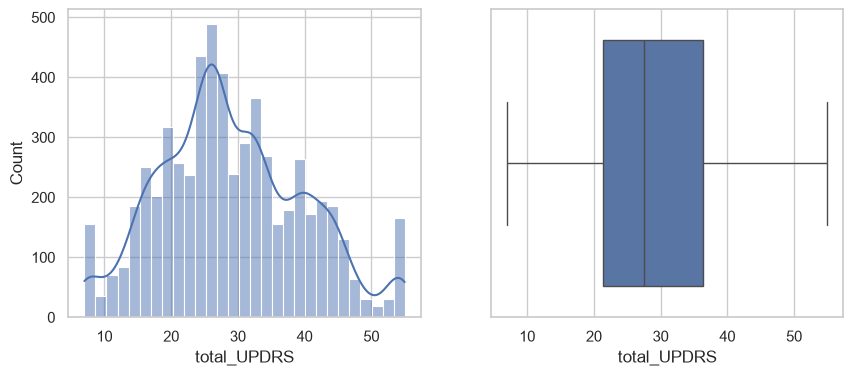

In [8]:
print("Skewness of total_UPDRS:", df[TARGET].skew())
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df[TARGET], kde=True, ax=ax[0])
sns.boxplot(x=df[TARGET], ax=ax[1])
plt.savefig(f"{FIG_DIR}/target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

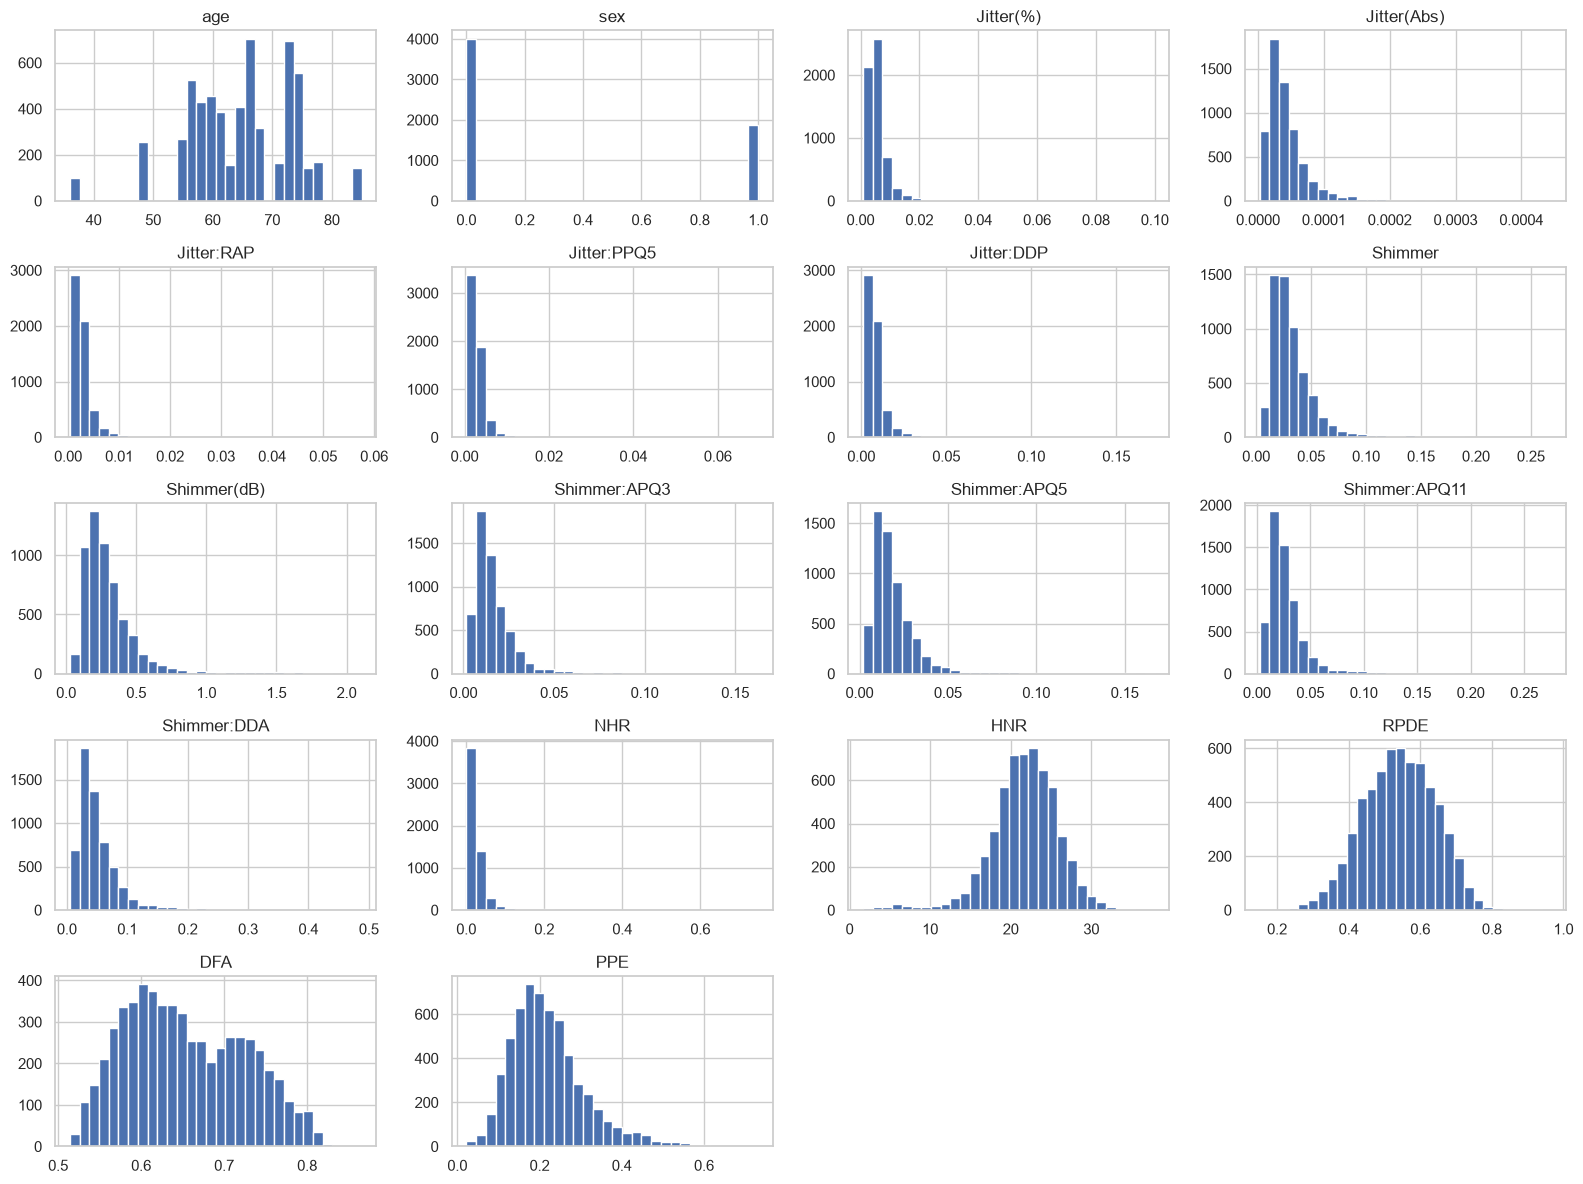

Jitter:PPQ5      7.586205
Jitter:RAP       6.945438
Jitter:DDP       6.945376
NHR              6.549123
Jitter(%)        6.451846
Shimmer:APQ5     3.698061
Shimmer:APQ11    3.406958
Shimmer          3.312793
Jitter(Abs)      3.283075
Shimmer(dB)      3.099221
Shimmer:DDA      3.097224
Shimmer:APQ3     3.097223
PPE              1.090819
sex              0.782873
DFA              0.282078
RPDE            -0.037434
age             -0.379133
HNR             -0.812057
dtype: float64


In [9]:
df[FEATURES].hist(bins=30, figsize=(16, 12))
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/feature_distributions.png", dpi=150)
plt.show()
print(df[FEATURES].skew().sort_values(ascending=False))

age              0.310290
HNR             -0.162117
RPDE             0.156897
PPE              0.156195
Shimmer:APQ11    0.120838
DFA             -0.113475
Shimmer(dB)      0.098790
sex             -0.096559
Shimmer          0.092141
Shimmer:APQ5     0.083467
Shimmer:DDA      0.079363
Shimmer:APQ3     0.079363
Jitter(%)        0.074247
Jitter(Abs)      0.066927
Jitter:DDP       0.064027
Jitter:RAP       0.064015
Jitter:PPQ5      0.063352
NHR              0.060952
Name: total_UPDRS, dtype: float64


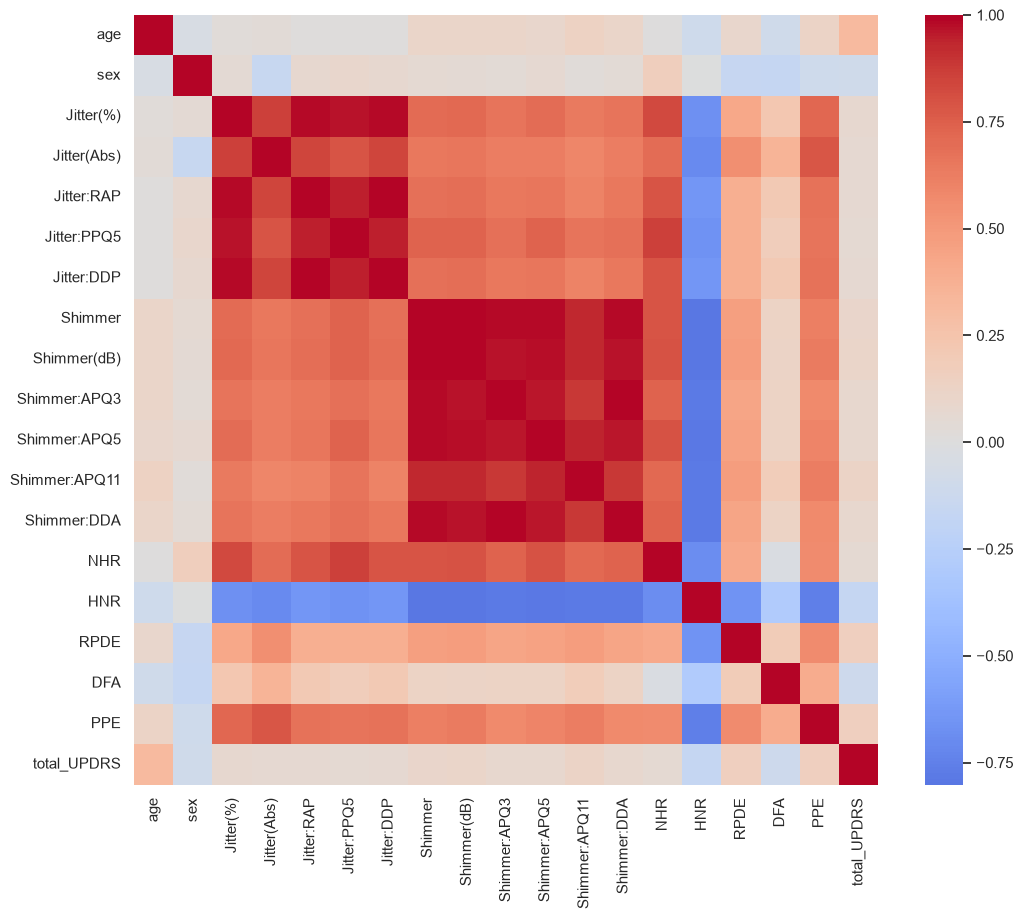

In [10]:
corr = df[FEATURES + [TARGET]].corr()
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False))

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.savefig(f"{FIG_DIR}/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
per_patient = df.groupby(GROUP_COL).size()
print("Patients:", per_patient.shape[0])
print(per_patient.describe())

patients = df.groupby(GROUP_COL).agg(age=("age", "first"), sex=("sex", "first"),
                                     mean_updrs=(TARGET, "mean"))
print(patients["age"].describe())
print(patients["sex"].value_counts())

Patients: 42
count     42.000000
mean     139.880952
std       15.542550
min      101.000000
25%      130.000000
50%      141.000000
75%      149.750000
max      168.000000
dtype: float64
count    42.000000
mean     64.404762
std       9.239521
min      36.000000
25%      58.000000
50%      65.000000
75%      72.000000
max      85.000000
Name: age, dtype: float64
sex
0    28
1    14
Name: count, dtype: int64


In [12]:
print("Std of total_UPDRS overall:", df[TARGET].std())
print("Std of patient means:", patients["mean_updrs"].std())

Std of total_UPDRS overall: 10.700283252298227
Std of patient means: 10.443513344916466


Cleaning

In [13]:
# 4.
df_clean = df.copy()

# 1. Duplicates: remove exact duplicate rows (if the EDA found any)
n_before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("Duplicates removed:", n_before - len(df_clean))

# 2. Drop the columns the sheet says to exclude
#    motor_UPDRS is almost equivalent to the target (leakage), test_time is excluded by the sheet
df_clean = df_clean.drop(columns=EXCLUDED)

# 3. Rename subject# to a cleaner name; it is used ONLY as the group, never as a feature
df_clean = df_clean.rename(columns={"subject#": "patient"})
GROUP_COL = "patient"

# 4. Check types: sex should be 0/1, patient an integer
df_clean["sex"] = df_clean["sex"].astype(int)
df_clean["patient"] = df_clean["patient"].astype(int)

print(df_clean.shape)
print(df_clean.dtypes.value_counts())
print("Sex values:", sorted(df_clean["sex"].unique()))

Duplicates removed: 0
(5875, 20)
float64    17
int64       3
Name: count, dtype: int64
Sex values: [np.int64(0), np.int64(1)]


In [14]:
assert "motor_UPDRS" not in FEATURES and "test_time" not in FEATURES
assert GROUP_COL not in FEATURES and TARGET not in FEATURES
print("Features:", len(FEATURES))   # should be 18

Features: 18


Splitting (reference split)

In [15]:
# 5. 
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(df_clean, groups=df_clean[GROUP_COL]))

df_clean["split_ref"] = "train"
df_clean.iloc[test_idx, df_clean.columns.get_loc("split_ref")] = "test"

train_df = df_clean[df_clean["split_ref"] == "train"]
test_df = df_clean[df_clean["split_ref"] == "test"]

X_train, y_train, groups_train = train_df[FEATURES], train_df[TARGET], train_df[GROUP_COL]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

# Sanity checks: no patient in both sets
assert set(train_df[GROUP_COL]).isdisjoint(set(test_df[GROUP_COL]))
print("Train:", len(train_df), "rows,", train_df[GROUP_COL].nunique(), "patients")
print("Test: ", len(test_df), "rows,", test_df[GROUP_COL].nunique(), "patients")

Train: 4640 rows, 33 patients
Test:  1235 rows, 9 patients


In [16]:
cv = GroupKFold(n_splits=5)
for i, (tr, va) in enumerate(cv.split(X_train, y_train, groups=groups_train)):
    p_tr = set(groups_train.iloc[tr]); p_va = set(groups_train.iloc[va])
    assert p_tr.isdisjoint(p_va)
    print(f"Fold {i+1}: {len(p_tr)} train patients, {len(p_va)} validation patients")

Fold 1: 27 train patients, 6 validation patients
Fold 2: 26 train patients, 7 validation patients
Fold 3: 26 train patients, 7 validation patients
Fold 4: 27 train patients, 6 validation patients
Fold 5: 26 train patients, 7 validation patients


In [17]:
df_clean.to_csv(CLEAN_PATH, index=False)
print("Saved:", CLEAN_PATH, df_clean.shape)

Saved: ../data/dataset_clean.csv (5875, 21)


Pipeline construction

Baseline

Hyperparameter search

Fina evaluation

Scaling

Split experiments

Optional ablation

Results excport